# Median price-per-m² baseline

No learning: predicted price = **median price per m²** of the listing's (property type, district) in the
training split × its `area_m2`. Groups with fewer than `MIN_GROUP` train rows fall back to the property type's
median, then the overall median.

This is roughly what a person does with a price list, so it's the floor: a model that can't clearly beat it
isn't learning anything beyond location + size.

In [1]:
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display

LAB = Path.cwd()
while not (LAB / "engines").is_dir():  # notebook lives in laboratory/engines/<model>/
    LAB = LAB.parent
sys.path.insert(0, str(LAB))
from engines.common import compare_table, load_config, load_splits, run_seeds

cfg = load_config()  # configs/neural_network_config.yml: same data split, seeds and features as the NN
SEEDS = cfg["data"].get("seeds") or [cfg["data"]["seed"]]
TARGET = cfg["data"]["target"]
FC = cfg["features"]
OUT = LAB / "models" / "median_baseline"

SERIES = ["#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#e87ba4", "#008300", "#6250d6", "#e34948"]
SURFACE, INK, INK2, MUTED, GRID, AXIS = "#fcfcfb", "#0b0b0b", "#52514e", "#898781", "#e1e0d9", "#c3c2b7"
plt.rcParams.update({
    "figure.facecolor": SURFACE, "axes.facecolor": SURFACE, "savefig.facecolor": SURFACE,
    "font.family": "sans-serif", "font.sans-serif": ["Segoe UI", "Helvetica", "Arial", "DejaVu Sans"],
    "font.size": 10, "text.color": INK, "axes.labelcolor": INK2, "axes.titlesize": 11,
    "axes.titleweight": "bold", "axes.titlelocation": "left", "axes.edgecolor": AXIS,
    "axes.spines.top": False, "axes.spines.right": False, "axes.grid": True, "grid.color": GRID,
    "grid.linewidth": 0.8, "axes.axisbelow": True, "xtick.color": MUTED, "ytick.color": MUTED,
    "xtick.labelcolor": INK2, "ytick.labelcolor": INK2, "lines.linewidth": 2, "legend.frameon": False,
    "figure.dpi": 110,
})
print("seeds", SEEDS, "->", OUT)

seeds [42, 7, 13, 21, 99] -> C:\Projects\CADT\property-valuation-model\laboratory\models\median_baseline


## Model

In [2]:
MIN_GROUP = 5  # min train rows for a (type, district) median

def fit(train, val, cfg, min_group=MIN_GROUP):
    """Returns predict(df) -> log price. val is unused: nothing to tune."""
    lppm = np.log(train[TARGET]) - np.log(train["area_m2"].clip(lower=1))   # log price per m2
    t = train.assign(lppm=lppm)
    g = t.groupby(["property_type", "district"]).lppm.agg(["median", "size"])
    by_td = g.loc[g["size"] >= min_group, "median"]
    by_t, overall = t.groupby("property_type").lppm.median(), t.lppm.median()

    def predict(df):
        key = pd.MultiIndex.from_frame(df[["property_type", "district"]])
        l = pd.Series(by_td.reindex(key).to_numpy(), index=df.index)
        l = l.fillna(df["property_type"].map(by_t)).fillna(overall)
        return (l + np.log(df["area_m2"].clip(lower=1))).to_numpy()
    predict.ppm = np.exp(by_td)  # $/m2 per (type, district) actually used
    return predict

## Train on every seed, score, save
`run_seeds` (in `engines/common.py`) does the same as the NN's `train.py`: for each seed it makes the same
train/val/test split, calls `fit`, scores with `regression_metrics` and writes

```
models/median_baseline/<name>/seed_<s>/metrics.json, test_predictions.csv
models/median_baseline/<name>/summary.json          mean / std over seeds
```

In [3]:
RUNS = ["base"]
summary, fitted = run_seeds(fit, cfg, OUT / "base")

[seed 42] test MdAPE 27.2%  RMSE log 0.553  R2 0.618


[seed 7] test MdAPE 28.2%  RMSE log 0.576  R2 0.519


[seed 13] test MdAPE 28.6%  RMSE log 0.557  R2 0.503


[seed 21] test MdAPE 28.2%  RMSE log 0.543  R2 0.629


[seed 99] test MdAPE 28.1%  RMSE log 0.569  R2 0.455


### How much does the group size matter?
Smaller groups = more local but noisier medians. Saved as extra runs so the comparison table shows them.

In [4]:
for g in (1, 20):
    print(f"min_group = {g}")
    run_seeds(lambda tr, va, c, g=g: fit(tr, va, c, g), cfg, OUT / f"min_group_{g}")

min_group = 1


[seed 42] test MdAPE 27.2%  RMSE log 0.549  R2 0.622


[seed 7] test MdAPE 28.2%  RMSE log 0.569  R2 0.562


[seed 13] test MdAPE 28.4%  RMSE log 0.549  R2 0.558


[seed 21] test MdAPE 28.1%  RMSE log 0.536  R2 0.639


[seed 99] test MdAPE 28.0%  RMSE log 0.560  R2 0.456
min_group = 20


[seed 42] test MdAPE 27.5%  RMSE log 0.568  R2 0.600
[seed 7] test MdAPE 28.5%  RMSE log 0.575  R2 0.509


[seed 13] test MdAPE 28.9%  RMSE log 0.578  R2 0.475
[seed 21] test MdAPE 28.3%  RMSE log 0.557  R2 0.616


[seed 99] test MdAPE 28.4%  RMSE log 0.585  R2 0.434


## Against the other models
Test split, mean ± std over the seeds, every run under `models/` trained on the same seeds (lower is better
except R²).

In [5]:
compare_table(SEEDS)

,MdAPE %,RMSE log,R²,MAE $
neural_network/base,23.0 ± 0.6,0.455 ± 0.014,0.683 ± 0.091,"121,471 ± 12,296"
median_baseline/min_group_1,28.0 ± 0.5,0.553 ± 0.012,0.567 ± 0.072,"146,501 ± 7,014"
median_baseline/base,28.1 ± 0.5,0.560 ± 0.013,0.545 ± 0.076,"148,883 ± 7,859"
median_baseline/min_group_20,28.3 ± 0.5,0.573 ± 0.011,0.527 ± 0.079,"152,597 ± 8,393"


### Typical % miss by property type (test MdAPE, mean over seeds)

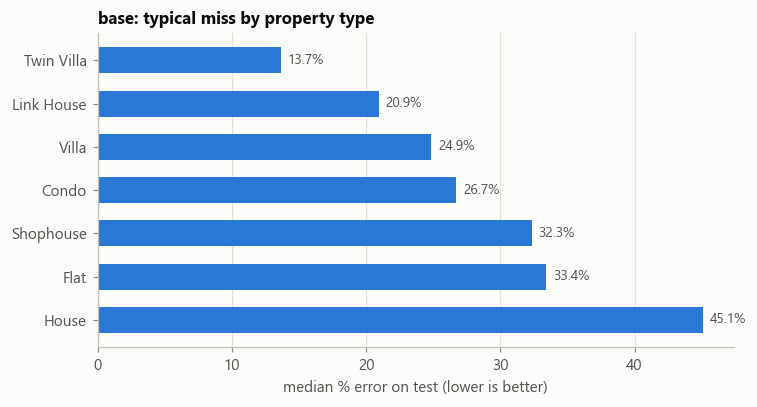

In [6]:
import json
summary = json.load(open(OUT / RUNS[0] / "summary.json"))["test"]
bt = pd.Series({t: m["median_ape"]["mean"] for t, m in summary.items() if t != "overall"}).sort_values()
fig, ax = plt.subplots(figsize=(7, 0.4 * len(bt) + 1))
ax.barh(bt.index, bt, color=SERIES[0], height=0.6)
ax.invert_yaxis()
ax.grid(axis="y", visible=False)
for y, v in enumerate(bt):
    ax.text(v + 0.5, y, f"{v:.1f}%", va="center", color=INK2, fontsize=9)
ax.set_xlabel("median % error on test (lower is better)")
ax.set_title(f"{RUNS[0]}: typical miss by property type")
plt.tight_layout()
plt.show()

### Median $/m² by district (first seed's train split; districts with a median for ≥ 3 types)

In [7]:
ppm = fitted[0].ppm.unstack("property_type")
ppm = ppm[ppm.notna().sum(axis=1) >= 3]
ppm = ppm.loc[ppm.median(axis=1).sort_values(ascending=False).index]
display(ppm.round(0).astype("Int64"))

property_type,Condo,Flat,House,Link House,Shophouse,Twin Villa,Villa
district,,,,,,,
7 Makara,1545,2721,3929,<NA>,6618,<NA>,4714
Chamkar Mon,1846,3483,3455,3750,4444,<NA>,4401
Boeng Keng Kang,1974,3606,3611,<NA>,4944,<NA>,5800
Daun Penh,1996,2717,3257,<NA>,6680,<NA>,6085
Tuol Kouk,1389,2834,2865,<NA>,4727,<NA>,3034
Mean Chey,1237,1419,1316,1874,3147,2459,2041
Chbar Ampov,1736,1006,1594,1800,2098,1740,1787
Sen Sok,1304,1544,1718,1787,2233,1938,1659
Russey Keo,1374,1502,1637,1667,2621,1708,1673
